In [1]:
from pathlib import Path

from glob import glob

from opensoundscape.visualization import inspect

/home/italo/open/shazam-da-natureza/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
dataset_path = Path("../data")
assert dataset_path.exists(), "Não conseguiu encontrar a pasta 'data'"

In [3]:
selection_files = glob(f"{dataset_path}/annotation_Files/*/*.txt")

audio_files: list[str] = [
    file.replace("annotation_Files", "mp3_Files").replace(
        ".Table.1.selections.txt", ".mp3"
    )
    for file in selection_files
]
audio_files[:3]

['../data/mp3_Files/Recording_3/Recording_3_Segment_01.mp3',
 '../data/mp3_Files/Recording_1/Recording_1_Segment_26.mp3',
 '../data/mp3_Files/Recording_1/Recording_1_Segment_24.mp3']

In [4]:
from opensoundscape.annotations import BoxedAnnotations

annotations = BoxedAnnotations.from_raven_files(
    raven_files=selection_files, audio_files=audio_files, annotation_column="Species"
)
annotations.df.head()

,audio_file,annotation_file,annotation,start_time,end_time,low_f,high_f,View,Selection,Channel
0,../data/mp3_Files/Recording_3/Recording_3_Segm...,../data/annotation_Files/Recording_3/Recording...,NOCA,0.24588,0.69425,1950.0,9600.0,Spectrogram 1,1,1
1,../data/mp3_Files/Recording_3/Recording_3_Segm...,../data/annotation_Files/Recording_3/Recording...,BWWA,0.250701,1.374037,5512.5,8887.5,Spectrogram 1,2,1
2,../data/mp3_Files/Recording_3/Recording_3_Segm...,../data/annotation_Files/Recording_3/Recording...,EATO,0.597827,0.906382,3112.5,4968.7,Spectrogram 1,3,1
3,../data/mp3_Files/Recording_3/Recording_3_Segm...,../data/annotation_Files/Recording_3/Recording...,EATO,0.887098,1.123335,2700.0,3768.7,Spectrogram 1,4,1
4,../data/mp3_Files/Recording_3/Recording_3_Segm...,../data/annotation_Files/Recording_3/Recording...,EATO,1.340289,2.632366,2400.0,9281.2,Spectrogram 1,5,1


In [7]:
clip_duration = 3
clip_overlap = 0
min_label_overlap = 0.25
species_of_interest = ["NOCA", "EATO", "SCTA", "BAWW", "BCCH", "AMCR", "NOFL"]

# Create dataframe of one-hot labels
clip_labels = annotations.clip_labels(
    clip_duration = clip_duration, 
    clip_overlap = clip_overlap,
    min_label_overlap = min_label_overlap,
    class_subset = species_of_interest # You can comment this line out if you want to include all species.
)
clip_labels.to_csv("clip_labels.csv")
clip_labels.head()

NOCA  \
file                                               start_time end_time         
../data/mp3_Files/Recording_3/Recording_3_Segme... 0.0        3.0       True   
                                                   3.0        6.0       True   
                                                   6.0        9.0       True   
                                                   9.0        12.0      True   
                                                   12.0       15.0      True   

                                                                        EATO  \
file                                               start_time end_time         
../data/mp3_Files/Recording_3/Recording_3_Segme... 0.0        3.0       True   
                                                   3.0        6.0       True   
                                                   6.0        9.0       True   
                                                   9.0        12.0      True   
                                                   12.0       15.0      True   

                                                                         SCTA  \
file                                               start_time end_time          
../data/mp3_Files/Recording_3/Recording_3_Segme... 0.0        3.0       False   
                                                   3.0        6.0       False   
                                                   6.0        9.0       False   
                                                   9.0        12.0      False   
                                                   12.0       15.0      False   

                                                                         BAWW  \
file                                               start_time end_time          
../data/mp3_Files/Recording_3/Recording_3_Segme... 0.0        3.0       False   
                                                   3.0        6.0       False   
                                                   6.0        9.0       False   
                                                   9.0        12.0      False   
                                                   12.0       15.0      False   

                                                                         BCCH  \
file                                               start_time end_time          
../data/mp3_Files/Recording_3/Recording_3_Segme... 0.0        3.0       False   
                                                   3.0        6.0       False   
                                                   6.0        9.0       False   
                                                   9.0        12.0      False   
                                                   12.0       15.0      False   

                                                                         AMCR  \
file                                               start_time end_time          
../data/mp3_Files/Recording_3/Recording_3_Segme... 0.0        3.0       False   
                                                   3.0        6.0       False   
                                                   6.0        9.0       False   
                                                   9.0        12.0      False   
                                                   12.0       15.0      False   

                                                                         NOFL  
file                                               start_time end_time         
../data/mp3_Files/Recording_3/Recording_3_Segme... 0.0        3.0       False  
                                                   3.0        6.0       False  
                                                   6.0        9.0       False  
                                                   9.0        12.0      False  
                                                   12.0       15.0      False

clips with Northern Cardinal (NOCA) labels:



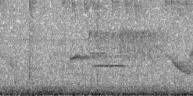
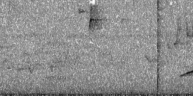
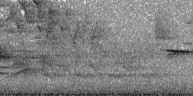
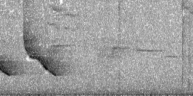

clips with Northern Flicker (NOFL) labels:



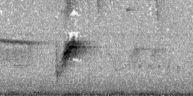
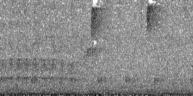
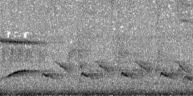
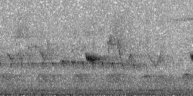

clips with none of the selected species (['NOCA', 'EATO', 'SCTA', 'BAWW', 'BCCH', 'AMCR', 'NOFL']) labeled:


/tmp/ipykernel_22360/1035943704.py:12: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  widget = inspect(clip_labels[clip_labels.sum(1) == 0], N=4, bandpass_range=(0, 8000))



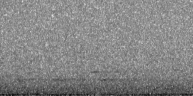
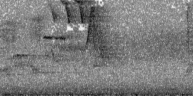
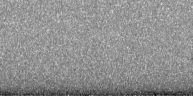
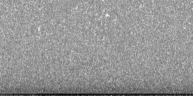

In [6]:
print(f"clips with Northern Cardinal (NOCA) labels:")
widget = inspect(
    clip_labels[clip_labels["NOCA"] == True], N=4, bandpass_range=(0, 8000)
)

print(f"clips with Northern Flicker (NOFL) labels:")
widget = inspect(
    clip_labels[clip_labels["NOFL"] == True], N=4, bandpass_range=(0, 8000)
)

print(f"clips with none of the selected species ({species_of_interest}) labeled:")
widget = inspect(clip_labels[clip_labels.sum(1) == 0], N=4, bandpass_range=(0, 8000))